# FoundationForecast (Anomaly Detection)

In [12]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[plot]"

## Import libraries

In [13]:
import pandas as pd

from foundationforecast import FoundationForecast


## Load the dataset

The DataFrame must include at least the following columns:
- unique_id: Unique identifier for each time series (string)
- ds: Date column (datetime format)
- y: Target variable for forecasting (float format)


In [14]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/the_anomaly_tour.csv",
    parse_dates=["ds"],
)
df

,unique_id,ds,y
0,Taylor Swift,2022-07-01,21499
1,Taylor Swift,2022-07-02,16349
2,Taylor Swift,2022-07-03,15042
3,Taylor Swift,2022-07-04,14358
4,Taylor Swift,2022-07-05,18332
...,...,...,...
6577,Selena Gomez,2025-06-27,8348
6578,Selena Gomez,2025-06-28,8670
6579,Selena Gomez,2025-06-29,9167
6580,Selena Gomez,2025-06-30,7902


## Import the models you want to use

In [15]:
from foundationforecast.models import Chronos, FlowState


## Create a FoundationForecast


In [16]:
ff = FoundationForecast(
    models=[
        Chronos(repo_id="amazon/chronos-bolt-mini"),
        FlowState(),
    ]
)

## Plot the data

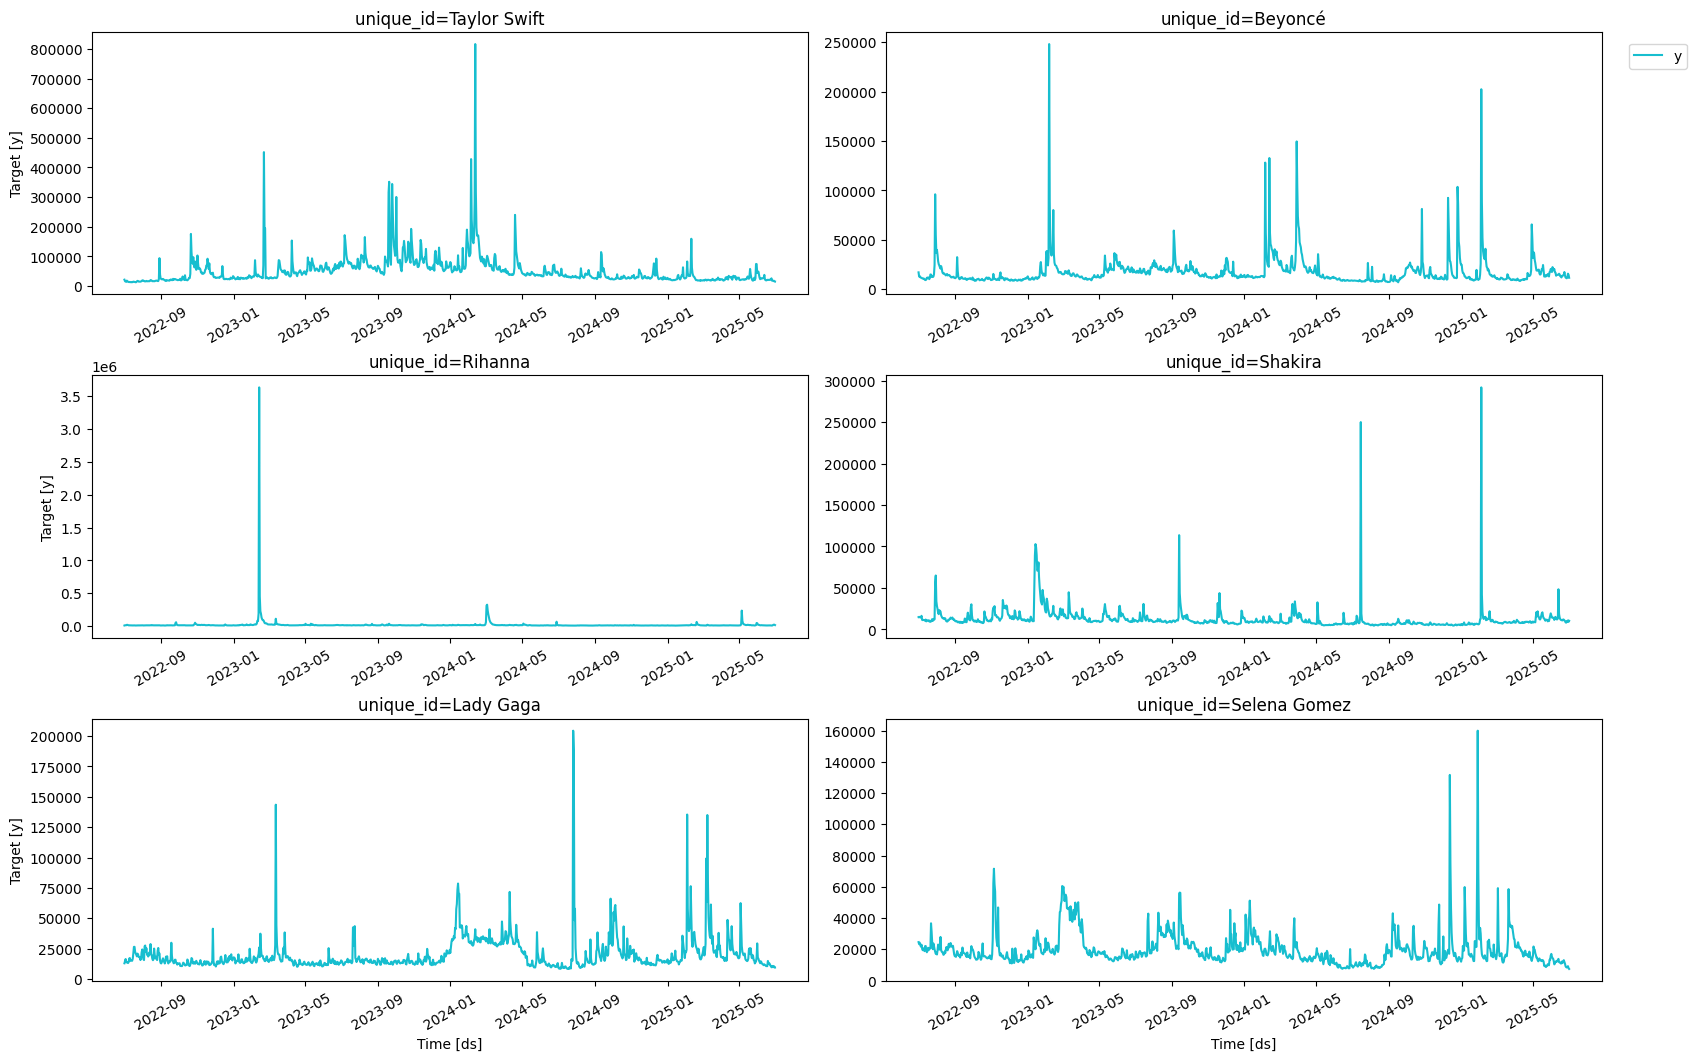

In [17]:
ff.plot(df)


## Detect anomalies

You can optionally specify the following parameters:
- freq: The frequency of your data (e.g., 'D' for daily, 'M' for monthly). If you skip it, it will be inferred by default.
- h: The forecast horizon, which is the number of periods to predict during cross validation (you can skip it, and it will use an inferred seasonality)


In [ ]:
anomalies_df = ff.detect_anomalies(df=df, h=7, level=99)

In [19]:
anomalies_df

,unique_id,ds,cutoff,y,Chronos,Chronos-lo-99,Chronos-hi-99,Chronos-anomaly,FlowState,FlowState-lo-99,FlowState-hi-99,FlowState-anomaly
0,Beyoncé,2022-07-06,2022-07-05,11571,11110.359375,-26138.335495,48359.054245,False,11127.579102,-25822.168881,48077.327084,False
1,Beyoncé,2022-07-07,2022-07-05,11046,11363.437500,-25885.257370,48612.132370,False,10919.441406,-26030.306576,47869.189389,False
2,Beyoncé,2022-07-08,2022-07-05,10874,11585.656250,-25663.038620,48834.351120,False,10822.109375,-26127.638608,47771.857358,False
3,Beyoncé,2022-07-09,2022-07-05,10471,11842.072266,-25406.622604,49090.767136,False,10851.082031,-26098.665951,47800.830014,False
4,Beyoncé,2022-07-10,2022-07-05,10721,12057.083008,-25191.611862,49305.777878,False,10776.775391,-26172.972592,47726.523373,False
...,...,...,...,...,...,...,...,...,...,...,...,...
6547,Taylor Swift,2025-06-27,2025-06-24,17837,21890.203125,-78560.299800,122340.706050,False,23186.814453,-74336.982277,120710.611183,False
6548,Taylor Swift,2025-06-28,2025-06-24,17536,21933.251953,-78517.250972,122383.754879,False,22668.996094,-74854.800636,120192.792824,False
6549,Taylor Swift,2025-06-29,2025-06-24,17960,21929.494141,-78521.008785,122379.997066,False,22706.505859,-74817.290871,120230.302589,False
6550,Taylor Swift,2025-06-30,2025-06-24,15490,22196.396484,-78254.106441,122646.899410,False,22523.238281,-75000.558449,120047.035011,False


## Plot results

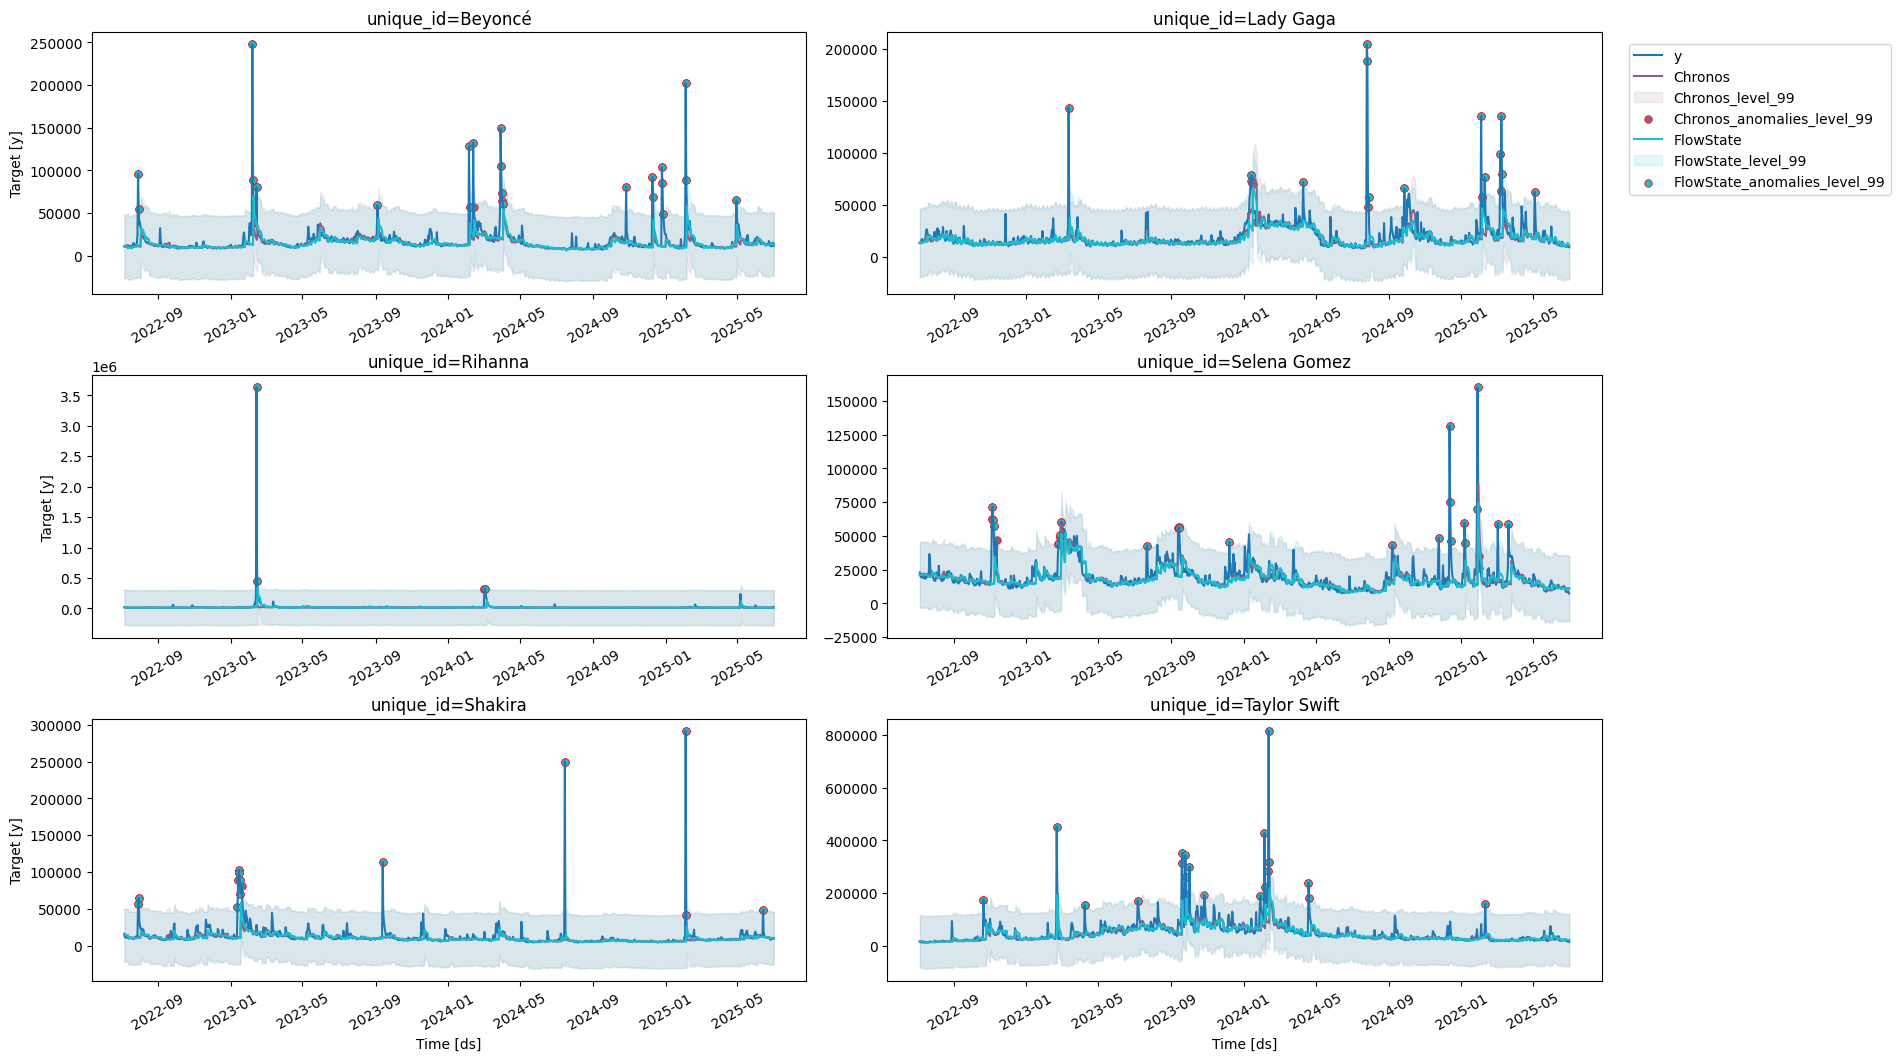

In [20]:
ff.plot(df, anomalies_df)